# Constitutional RAG

## Prerequisits

In [14]:
# imports
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_ollama import OllamaEmbeddings
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from numpy.linalg import norm
import pymupdf
import os
import re 

# Miscellaneous

In [15]:
# --- 1. The "Bulletproof" PDF Cleaning Function ---
def clean_pdf_text(text: str) -> str:
    # 1. Replace tabs with spaces
    text = text.replace('\t', ' ')
    
    # 2. Fix words broken by hyphens at line breaks (e.g., "con-\nstitution")
    text = re.sub(r'(\w+)-\n(\w+)', r'\1\2', text)
    
    # 3. Remove isolated page numbers (lines containing ONLY a number)
    text = re.sub(r'^\s*\d{1,4}\s*$', '', text, flags=re.MULTILINE)
    
    # 4. Remove running headers/footers (e.g., "Chapter 1: Founding Provisions")
    text = re.sub(r'(?m)^\s*Chapter \d+:\s+[A-Za-z ]+\s*$', '', text)
    
    # 5. THE MAGIC TRICK: Fix PDF line-wraps without losing paragraph breaks
    # PDFs put a single \n at the end of every visual line. We want to turn those into spaces,
    # but keep the double \n\n that separate actual paragraphs.
    text = text.replace('\n\n', '[[PARA]]')  # Temporarily hide real paragraphs
    text = text.replace('\n', ' ')           # Turn visual line-breaks into spaces
    text = text.replace('[[PARA]]', '\n\n')  # Restore real paragraphs
    
    # 6. Collapse multiple spaces into a single space
    text = re.sub(r' +', ' ', text)
    
    return text.strip()


def clean_toc_index(raw_text):
    # Strip the "Junk" (Table of Contents & Title Page)
    preamble_marker = "PREAMBLE\nWe, the people of South Africa"
    preamble_index = raw_text.find(preamble_marker)

    if preamble_index != -1:
        raw_text = raw_text[preamble_index:]

    # --- NEW: Strip the Index (appears at the end) ---
    # Look for "INDEX" as a standalone heading
    index_marker = "\nINDEX\n"
    index_position = raw_text.find(index_marker)

    if index_position != -1:
        raw_text = raw_text[:index_position]
        print(f"✓ Removed Index starting at position: {index_position}")
    else:
        # Try alternative formats
        alt_markers = ["\nI N D E X\n", "\nINDEX\n\n", "INDEX\n"]
        for marker in alt_markers:
            index_position = raw_text.find(marker)
            if index_position != -1:
                raw_text = raw_text[:index_position]
                print(f"✓ Removed Index using alternative marker")
                break

    return raw_text

## Loading, Cleaning & Metadata 

In [25]:
# --- 1.  File path
file_path = "../data/RSAConstitution-eng_p01-10.pdf"


# --- 2. Extract Text using PyMuPDF ---
doc = pymupdf.open(file_path)
raw_text = ""
for page in doc:
    raw_text += page.get_text("text") + "\n"


# --- 3. Strip the "Junk" (Table of Contents & Title Page) ---
# Clean toc and index
clean_text = clean_toc_index(raw_text)

# Clean the text
text = clean_pdf_text(clean_text)


# --- 4. Chapter metadata ---
chapter_pattern = r'CHAPTER\s+\d+\s+[A-Z][A-Z\s\-]*?(?=\s+[A-Z][a-z]|\s+\d+\.)'

# Find all chapter headings and their positions
matches = list(re.finditer(chapter_pattern, text))
print(f"\n✓ Found {len(matches)} chapters")

# Build chapter documents by slicing the text
chapter_documents = []
current_chapter = "PREAMBLE"
current_start = 0

for match in matches:
    # 1. Save the content BEFORE this chapter (belongs to previous chapter)
    if current_start < match.start():
        content = text[current_start:match.start()].strip()
        if content:
            chapter_documents.append(Document(
                page_content=content,
                metadata={
                    "source": "RSA Constitution 1996",
                    "document_type": "legal",
                    "chapter": current_chapter
                }
            ))
    
    # 2. Update current chapter
    # We use match.start() so the chapter heading is INCLUDED in its own content
    current_chapter = match.group(0).strip()
    current_start = match.start()

# 3. Don't forget the last chapter (after the final match)
if current_start < len(text):
    content = text[current_start:].strip()
    if content:
        chapter_documents.append(Document(
            page_content=content,
            metadata={
                "source": "RSA Constitution 1996",
                "document_type": "legal",
                "chapter": current_chapter
            }
        ))

print(f"✓ Split into {len(chapter_documents)} chapter documents")


# --- 5. Configure the Text Splitter (Simplified to prevent micro-chunking) ---
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100,
    separators=[
        r"\n\n(?=\d+\.\s+[A-Z])",  # 1. Main sections (e.g., "9. Equality")
        "\n\n",                   # 2. Paragraph breaks
        " ",                      # 3. Spaces (prevents breaking mid-sentence)
        ""                        # 4. Characters (last resort)
    ],
    is_separator_regex=True,
)


# --- 6. Split and Filter ---
text_chunks = text_splitter.split_documents(chapter_documents)


# --- 7. Proof it works
print(f"\n✓ Total chunks: {len(text_chunks)}")

# Show a sample from different chapters
print("\n--- SAMPLE CHUNKS WITH METADATA ---")
seen_chapters = set()
for chunk in text_chunks:
    chapter = chunk.metadata['chapter']
    if chapter not in seen_chapters:
        seen_chapters.add(chapter)
        print(f"\nChapter: {chapter}")
        print(f"Preview: {chunk.page_content[:120]}...")
        if len(seen_chapters) >= 10:  # Show first 4 different chapters
            break

print(text_chunks[0].page_content)


✓ Found 2 chapters
✓ Split into 3 chapter documents

✓ Total chunks: 10

--- SAMPLE CHUNKS WITH METADATA ---

Chapter: PREAMBLE
Preview: PREAMBLE We, the people of South Africa, Recognise the injustices of our past; Honour those who suffered for justice and...

Chapter: CHAPTER 1 FOUNDING PROVISIONS
Preview: CHAPTER 1 FOUNDING PROVISIONS Republic of South Africa 1. The Republic of South Africa is one, sovereign, democratic sta...

Chapter: CHAPTER 2 BILL OF RIGHTS
Preview: CHAPTER 2 BILL OF RIGHTS Rights 7. (1) This Bill of Rights is a cornerstone of democracy in South Africa. It enshrines t...
PREAMBLE We, the people of South Africa, Recognise the injustices of our past; Honour those who suffered for justice and freedom in our land; Respect those who have worked to build and develop our country; and Believe that South Africa belongs to all who live in it, united in our diversity. We therefore, through our freely elected representatives, adopt this Constitution as the supreme law of t

## Embeddings

### 1. Mapping the Linguistic Meaning of Text Chunks to a Numerical Representation

In [17]:
# --- 1. Instantiate the embedding model ---
embed = OllamaEmbeddings(model="qwen3-embedding:0.6b")

# --- 2.  Create a list for the embeddings created ---
embeddings = []

# Interate through the chunks and create vectors of them
for text_chunk in text_chunks:
    vector = embed.embed_query(text_chunk.page_content)
    embeddings.append(vector)

# --- 3. Proof it works ---
print(embeddings)
print(f"Lenght of embeddings: {len(embeddings[0])}")

[[0.012311617, -0.09715445, -0.0068276143, 0.011406966, -0.025981972, -0.08316459, -0.007963989, -0.017348874, -0.035490934, -0.063551836, -0.12013204, 0.007575156, 0.076115675, -0.00805656, -0.030281872, 0.009119939, -0.039252084, 0.03891784, 0.03604274, -0.10923361, 0.00481198, -0.020744238, 0.078167975, 0.0604943, -0.0035607289, 0.02075226, 0.019909644, 0.032980077, 0.079529196, -0.042982973, 0.00095417246, -0.0033057006, -0.0089573935, -0.0075787124, 0.0003806878, -0.010472703, 0.033965208, -0.015148751, 0.021749565, 0.0009246969, -0.01907998, -0.006587103, -0.06338696, 0.033503786, -0.05167489, -0.009208918, -0.008722489, -0.0537076, -0.028862711, 0.029565189, -0.035243466, -0.0033264246, 0.03904146, -0.0062625473, 0.044324853, 0.024297714, 0.042378232, -0.026198106, -0.020253032, -0.015019375, 0.026689475, 0.060160454, 0.013213551, -0.022187868, 0.008733857, 0.021693373, -0.045742884, 0.00094196835, 0.0017027523, -0.018304905, 0.0014717586, 0.040515777, -0.019200258, 0.012645767,

### 2. Visualizing Semantic Relationships Between Text Chunks via Dimensionality Reduction Techniques

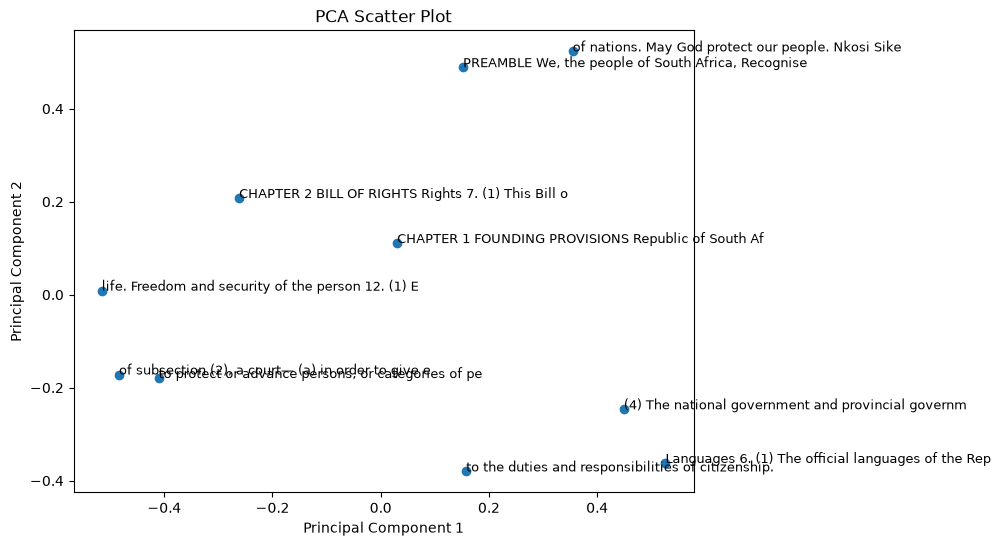

In [18]:
# --- 1. Convert embeddings to DataFrames ---
# Each row represents one text chunk, each column one embedding dimension
embeddings_df =  pd.DataFrame(embeddings, columns=[f"dim{i}" for i in range(len(embeddings[0]))])


# --- 2. Perfom "Principal Component Analysis (PCA)" with 2 components --- 
pca = PCA(n_components=2)
df_reduced = pca.fit_transform(embeddings_df)


# --- 3. Create new DataFrame with reduced dimensions ---
df_reduced = pd.DataFrame(df_reduced, columns=["PC1", "PC2"])
df_reduced["text"] = text_chunks                         # Add original chunks for labelling

# Create scatter plot
plt.figure(figsize=(8,6))
plt.scatter(df_reduced["PC1"], df_reduced["PC2"])

# Add labels to each point
for i, label in enumerate(df_reduced["text"]):
    plt.text(df_reduced["PC1"][i], df_reduced["PC2"][i], label.page_content[:50], fontsize=9)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Scatter Plot")

# --- 4. Save plot ---
plt.savefig("../visualisations/principal_component_plot.svg", format="svg")

### 3. Calculating the Distance Between Embeddings

### Helper functions

In [35]:
# --- 1. Create vector for chunks ---
def create_embeddings(text_chunk, client):
    return client.embed_query(text_chunk)


# --- 2. Calculate cosine similarity by using Numpy ---
def calculate_cosine_similarity(text_chunk_embedding, users_question_embedding):
    A = text_chunk_embedding
    B = users_question_embedding

    # Calculate the cosine similarity
    cosine = np.dot(A, B) / (norm(A) * norm(B))

    return cosine

In [36]:
# --- 1. Create embeddings function ---
client = OllamaEmbeddings(model="qwen3-embedding:0.6b")


# Create a for loop to save the text chunks
text_chunks_list = []

for chunk in text_chunks:
    text_chunks_list.append(chunk.page_content)


# --- 2. Create a test question and create the pandas DataFrame
users_question = "What are the national flag colours?"
new_embeddings_df = pd.DataFrame(text_chunks_list, columns=["text_chunk"])


# --- 3. Apply function 'create_embeddings' to the correct column ---
new_embeddings_df["embedding"] = new_embeddings_df["text_chunk"].apply(create_embeddings, client=client)

# Create embedding for the 'user_question'
users_question_embedding = create_embeddings(users_question, client)


# --- 4. Apply function 'calculate_cosine_similarity' to the correct column ---
new_embeddings_df["similarity"] = new_embeddings_df["embedding"].apply(calculate_cosine_similarity, users_question_embedding=users_question_embedding)


# --- 5. Proof it works ---
print(f"User question embeddings: {users_question_embedding}")

new_embeddings_df

User question embeddings: [0.009107526, -0.06895811, -0.009629162, -0.05907725, 0.03910197, -0.013378056, 0.023450421, -0.02342819, -0.045319077, -0.04136312, -0.020566378, -0.017686684, 0.0336851, -0.009106396, -0.043599993, 0.06341334, 0.018470665, 0.072159946, 0.08791702, -0.09856126, -0.015803043, -0.024033008, -0.0147699, 0.081724964, 0.037486564, -0.012801367, -0.018363645, 0.036439728, 0.0085840365, -0.027882947, 0.03883008, -0.017419636, -0.03698131, -0.012220126, 0.029152602, -0.012675706, 0.035319135, -0.019825557, -0.0014148838, 0.048266828, -0.0033546917, 0.031708956, -0.12309497, 0.025642795, -0.009143866, -0.032861784, 0.018258397, 0.042478915, -0.040003005, -0.030857317, -0.04347378, -0.04441363, -0.00020283311, -0.003884483, 0.03088182, -0.019115316, 0.03826732, 0.015687414, -0.012190624, -0.004221831, -0.046597596, 0.040073156, -0.0019771785, -0.0022810395, -0.012761247, 0.027873462, -0.020087793, -0.009626706, -0.057796184, -0.01136342, -0.0010549758, 0.016880307, -0.

,text_chunk,embedding,similarity
0,"PREAMBLE We, the people of South Africa, Recog...","[0.012311617, -0.09715445, -0.0068276143, 0.01...",0.281583
1,of nations. May God protect our people. Nkosi ...,"[0.020498395, -0.044979285, -0.0062887105, -0....",0.305981
2,CHAPTER 1 FOUNDING PROVISIONS Republic of Sout...,"[0.0096508395, -0.10834845, -0.0049967878, -0....",0.268443
3,to the duties and responsibilities of citizens...,"[0.013032078, -0.088042066, -0.008622631, -0.0...",0.598112
4,Languages 6. (1) The official languages of the...,"[-0.008556165, -0.13418868, -0.009651877, -0.0...",0.382450
5,(4) The national government and provincial gov...,"[-0.03989692, -0.12548265, -0.008828457, -0.01...",0.324694
6,CHAPTER 2 BILL OF RIGHTS Rights 7. (1) This Bi...,"[-0.06177383, -0.07442717, -0.003416012, -0.04...",0.244428
7,"of subsection (2), a court— (a) in order to gi...","[-0.03373734, -0.07304374, -0.002425525, -0.02...",0.169543
8,"to protect or advance persons, or categories o...","[-0.009481924, -0.040455844, -0.00026827166, 0...",0.202413
9,life. Freedom and security of the person 12. (...,"[-0.04017271, -0.023756206, -0.0024215006, 0.0...",0.126087
